In [88]:
import numpy as np
import matplotlib.pyplot as plt
import pylcp
from scipy.interpolate import RegularGridInterpolator

class MOT:
    def __init__(self, det=-1.5, s=4.0, alpha=2.0, N_atoms=300, mass=1.0, r_c=1.0, v_c=0.5, dt=0.05,
                 nsteps=1000, grid_extent=5, grid_step=0.2, Fg = 1, Fe = 2, gFg = 0, gFe = 1/2, mu = 1):

        # Simulation parameters
        self.det = det #detuning 
        self.s = s #saturation ratio (i.e. I/I_sat)
        self.alpha = alpha #magnetic field gradient
        self.N_atoms = N_atoms #number of atoms in the system
        self.mass = mass #mass of the atoms in the system -- defaults to 1
        self.r_c = r_c #minimum distance from center to be considered "trapped"
        self.v_c = v_c #minimum velocity to be considered "trapped"
        self.dt = dt #time step (used for integration)
        self.nsteps = nsteps #total number of simulation steps

        # use mesh grid to keep track of positions and velocities 
        self.x_grid = np.arange(-grid_extent, grid_extent + grid_step, grid_step)
        self.v_grid = np.arange(-grid_extent, grid_extent + grid_step, grid_step)
        self.X, self.V = np.meshgrid(self.x_grid, self.v_grid)

        #initializes all the necessary pylcp options 
        self._init_pylcp_objects()

        # computes Fx, Fy, Fz
        self._compute_force_maps()

        # initalizes the atoms 
        self._init_atoms()

        #lists to keep track of position and velocity in all dimensions
        self.positions_x = [self.x_atoms.copy()]
        self.positions_y = [self.y_atoms.copy()]
        self.positions_z = [self.z_atoms.copy()]

        self.velocities_x = [self.vx_atoms.copy()]
        self.velocities_y = [self.vy_atoms.copy()]
        self.velocities_z = [self.vz_atoms.copy()]

        # additional lists to track time and the number of trapped atoms (defined by r_c and v_c)
        self.times = []
        self.trapped_counts = []

    
    def _init_pylcp_objects(self, Fg = 1, Fe = 2, gFg = 0, gFe = 1/2, mu = 1):
        """
        Creates all the pylcp objects that will be needed everytime a MOT is created (e.g. laser beams, 
        magnetic field, hamiltonian, and the rate equation)
        
        Input parameters:
        Fg = ground state F value
        Fe = excited state F value
        gFg = lande-g factor for ground state
        gFe = lande-g factor for excited state
        mu = bohr magneton
        """
        #initalizes the laser beams necessary for a 3D MOT
        self.laserBeams = pylcp.conventional3DMOTBeams(
            delta=self.det, s=self.s,
            beam_type=pylcp.infinitePlaneWaveBeam
        )

        #initalizes the magnetic field based on the alpha value
        self.magField = pylcp.quadrupoleMagneticField(self.alpha)

        #returns hamiltonian (for the respective hyperfine state) and the magnetic dipole for the given state
        Hg, Bgq = pylcp.hamiltonians.singleF(F=Fg, gF=gFg, muB=mu)
        He, Beq = pylcp.hamiltonians.singleF(F=Fe, gF=gFe, muB=mu)
        
        #calcluates the transition amplitude for given states
        dijq = pylcp.hamiltonians.dqij_two_bare_hyperfine(Fg, Fe)

        #constructs the full hamiltonian with necessary operators 
        self.hamiltonian = pylcp.hamiltonian(Hg, He, Bgq, Beq, dijq)

        #solves for the system
        self.rateeq = pylcp.rateeq(
            self.laserBeams,
            self.magField,
            self.hamiltonian,
            svd_eps=1e-10,
            include_mag_forces=False
        )

    def _compute_1d_force(self, axis_index):
        """
        Computes the force profile at steady state for a given axis
        """
        coords = [np.zeros(self.X.shape), np.zeros(self.X.shape), np.zeros(self.X.shape)]
        vels   = [np.zeros(self.V.shape), np.zeros(self.V.shape), np.zeros(self.V.shape)]

        coords[axis_index] = self.X
        vels[axis_index]   = self.V

        axis_name = ["Fx", "Fy", "Fz"][axis_index]

        self.rateeq.generate_force_profile(coords, vels, name=axis_name) #calculates the steady state value for the given axis and stores in the rateeq dictionary
        return self.rateeq.profile[axis_name].F[axis_index] # returns the steady state value of the force for the given axis


    def _compute_force_maps(self):
        """
        Makes the forces continuous for plotting
        """
        self.Fx = self._compute_1d_force(0)
        self.Fy = self._compute_1d_force(1)
        self.Fz = self._compute_1d_force(2)

        self.interp_Fx = RegularGridInterpolator(
            (self.v_grid, self.x_grid), self.Fx, bounds_error=False, fill_value=0
        )
        self.interp_Fy = RegularGridInterpolator(
            (self.v_grid, self.x_grid), self.Fy, bounds_error=False, fill_value=0
        )
        self.interp_Fz = RegularGridInterpolator(
            (self.v_grid, self.x_grid), self.Fz, bounds_error=False, fill_value=0
        )


    def _init_atoms(self, x_min = -2, x_max = 2, y_min = -2, y_max = 2, z_min = -2, z_max = 2, vx_min = -1, vx_max = 1, vy_min = -1, vy_max = 1, vz_min = -1, vz_max = 1):
        """
        Initializes the atoms' positions and velocities at random values in the given range
        """
        self.x_atoms = np.random.uniform(x_min, x_max, self.N_atoms)
        self.y_atoms = np.random.uniform(y_min, y_max, self.N_atoms)
        self.z_atoms = np.random.uniform(z_min, z_max, self.N_atoms)

        self.vx_atoms = np.random.uniform(vx_min, vx_max, self.N_atoms)
        self.vy_atoms = np.random.uniform(vy_min, vy_max, self.N_atoms)
        self.vz_atoms = np.random.uniform(vz_min, vz_max, self.N_atoms)


    # def step(self):
    #     """
    #     Computes the position and velocity after one step 
    #     """
    #     # forces
    #     Fx_now = self.interp_Fx(np.column_stack((self.vx_atoms, self.x_atoms)))
    #     Fy_now = self.interp_Fy(np.column_stack((self.vy_atoms, self.y_atoms)))
    #     Fz_now = self.interp_Fz(np.column_stack((self.vz_atoms, self.z_atoms)))

    #     # calculates the acceleration in each direction
    #     ax = Fx_now / self.mass
    #     ay = Fy_now / self.mass
    #     az = Fz_now / self.mass

    #     # updates the velocity using v = v_0 + at
    #     self.vx_atoms += ax * self.dt
    #     self.vy_atoms += ay * self.dt
    #     self.vz_atoms += az * self.dt

    #     # updates the position using x = x_0 + vt
    #     self.x_atoms += self.vx_atoms * self.dt
    #     self.y_atoms += self.vy_atoms * self.dt
    #     self.z_atoms += self.vz_atoms * self.dt

    #     # stores final values
    #     self.positions_x.append(self.x_atoms.copy())
    #     self.positions_y.append(self.y_atoms.copy())
    #     self.positions_z.append(self.z_atoms.copy())

    #     self.velocities_x.append(self.vx_atoms.copy())
    #     self.velocities_y.append(self.vy_atoms.copy())
    #     self.velocities_z.append(self.vz_atoms.copy())

    #     # calculates the magnitude of the position and velocity vector (used to identify if the atom is trapped)
    #     r = np.sqrt(self.x_atoms**2 +
    #                 self.y_atoms**2 +
    #                 self.z_atoms**2)
    #     vmag = np.sqrt(self.vx_atoms**2 +
    #                    self.vy_atoms**2 +
    #                    self.vz_atoms**2)

    #     # identifies if the atom has been trapped and then appends the count to the total 
    #     trapped = np.logical_and(r < self.r_c, vmag < self.v_c)
    #     self.trapped_counts.append(np.sum(trapped))

    def step(self):
    
        # allocate force arrays
        Fx = np.zeros(self.N_atoms)
        Fy = np.zeros(self.N_atoms)
        Fz = np.zeros(self.N_atoms)
    
        # loop over atoms
        for i in range(self.N_atoms):
    
            r = np.array([self.x_atoms[i],
                          self.y_atoms[i],
                          self.z_atoms[i]])
    
            v = np.array([self.vx_atoms[i],
                          self.vy_atoms[i],
                          self.vz_atoms[i]])
    
            # steady-state populations
            rho = self.rateeq.equilibrium_populations(r, v, t=0)
    
            # F = (force_vec, details_dict, mag_force)
            F_tuple = self.rateeq.force(r, 0.0, rho)
    
            F_vec = F_tuple[0]   
    
            Fx[i], Fy[i], Fz[i] = F_vec
    
        # convert forces to accelerations
        ax = Fx / self.mass
        ay = Fy / self.mass
        az = Fz / self.mass
    
        # update velocities
        self.vx_atoms += ax * self.dt
        self.vy_atoms += ay * self.dt
        self.vz_atoms += az * self.dt
    
        # update positions
        self.x_atoms += self.vx_atoms * self.dt
        self.y_atoms += self.vy_atoms * self.dt
        self.z_atoms += self.vz_atoms * self.dt
    
        # store trajectories
        self.positions_x.append(self.x_atoms.copy())
        self.positions_y.append(self.y_atoms.copy())
        self.positions_z.append(self.z_atoms.copy())
    
        self.velocities_x.append(self.vx_atoms.copy())
        self.velocities_y.append(self.vy_atoms.copy())
        self.velocities_z.append(self.vz_atoms.copy())
    
        # trapping check
        rmag = np.sqrt(self.x_atoms**2 + self.y_atoms**2 + self.z_atoms**2)
        vmag = np.sqrt(self.vx_atoms**2 + self.vy_atoms**2 + self.vz_atoms**2)
    
        trapped = (rmag < self.r_c) & (vmag < self.v_c)
        self.trapped_counts.append(np.sum(trapped))


    def run(self):
        """
        runs the simulation by completeing as many steps as initally initialized (default is 150)
        """
        for step in range(self.nsteps):
            self.step()
            self.times.append(step * self.dt)

        # convert lists to arrays which is necessary for plotting
        self.positions_x = np.array(self.positions_x)
        self.positions_y = np.array(self.positions_y)
        self.positions_z = np.array(self.positions_z)

        self.velocities_x = np.array(self.velocities_x)
        self.velocities_y = np.array(self.velocities_y)
        self.velocities_z = np.array(self.velocities_z)

# constructed a series of plotting functions for each direction as well as the total atoms trapped

    def plot_z_vz(self):
        fig, ax = plt.subplots(figsize=(6, 5))

        im = ax.imshow(
            self.Fz,
            extent=(self.x_grid.min(), self.x_grid.max(),
                    self.v_grid.min(), self.v_grid.max()),
            origin='lower',
            aspect='auto',
            cmap='RdBu_r',
            vmin=-0.3,
            vmax=0.3
        )

        for i in range(self.N_atoms):
            ax.plot(self.positions_z[:, i], self.velocities_z[:, i],
                    lw=0.6, alpha=0.6)

        ax.set_title("z–vz Trajectories")
        ax.set_xlabel("z")
        ax.set_ylabel("vz")

        cbar = fig.colorbar(im, ax=ax)
        cbar.set_label("Optical Force Fz")

        plt.tight_layout()
        plt.show()

    def plot_x_vx(self):
        fig, ax = plt.subplots(figsize=(6, 5))

        im = ax.imshow(
            self.Fx,
            extent=(self.x_grid.min(), self.x_grid.max(),
                    self.v_grid.min(), self.v_grid.max()),
            origin='lower',
            aspect='auto',
            cmap='RdBu_r',
            vmin=-0.3,
            vmax=0.3
        )

        for i in range(self.N_atoms):
            ax.plot(self.positions_x[:, i], self.velocities_x[:, i],
                    lw=0.6, alpha=0.6)

        ax.set_title("x–vx Trajectories")
        ax.set_xlabel("x")
        ax.set_ylabel("vx")

        cbar = fig.colorbar(im, ax=ax)
        cbar.set_label("Optical Force Fx")

        plt.tight_layout()
        plt.show()

    def plot_y_vy(self):
        fig, ax = plt.subplots(figsize=(6, 5))

        im = ax.imshow(
            self.Fy,
            extent=(self.x_grid.min(), self.x_grid.max(),
                    self.v_grid.min(), self.v_grid.max()),
            origin='lower',
            aspect='auto',
            cmap='RdBu_r',
            vmin=-0.3,
            vmax=0.3
        )

        for i in range(self.N_atoms):
            ax.plot(self.positions_y[:, i], self.velocities_y[:, i],
                    lw=0.6, alpha=0.6)

        ax.set_title("y–vy Trajectories")
        ax.set_xlabel("y")
        ax.set_ylabel("vy")

        cbar = fig.colorbar(im, ax=ax)
        cbar.set_label("Optical Force Fy")

        plt.tight_layout()
        plt.show()

    def plot_trapped(self):
        fig, ax = plt.subplots(figsize=(6, 4))

        ax.plot(self.times, self.trapped_counts,
                lw=2, color='darkgreen')

        ax.set_xlabel("time")
        ax.set_ylabel("atoms trapped")
        ax.set_title("Trapping vs Time")
        ax.grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

    def animate_3D(self):
        fig = plt.figure(figsize=(7,7))
        ax = fig.add_subplot(111, projection='3d')
    
        # initial frame
        scat = ax.scatter(
            self.positions_x[0],
            self.positions_y[0],
            self.positions_z[0],
            c='blue', s=8
        )
    
        # axis limits (fixed)
        ax.set_xlim(self.positions_x.min(), self.positions_x.max())
        ax.set_ylim(self.positions_y.min(), self.positions_y.max())
        ax.set_zlim(self.positions_z.min(), self.positions_z.max())
    
        def update(frame):
            scat._offsets3d = (
                self.positions_x[frame],
                self.positions_y[frame],
                self.positions_z[frame]
            )
            ax.set_title(f"Frame {frame}")
            return scat,
    
        ani = FuncAnimation(
            fig,
            update,
            frames=len(self.positions_x),
            interval=60,
            blit=False
        )
        ani.save("mot_animation.gif", writer="pillow")
    
        return ani


In [89]:
mot = MOT()
mot.run()

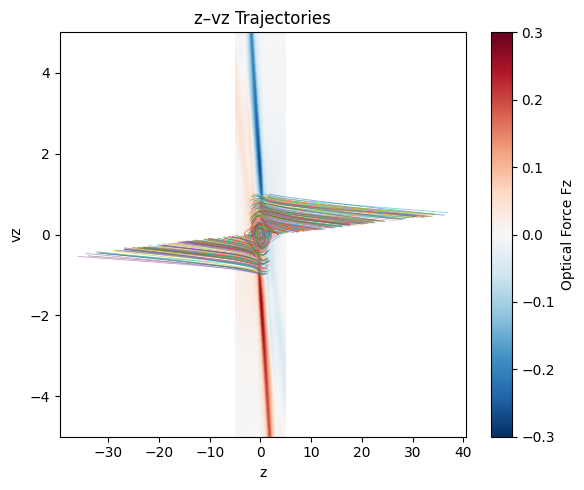

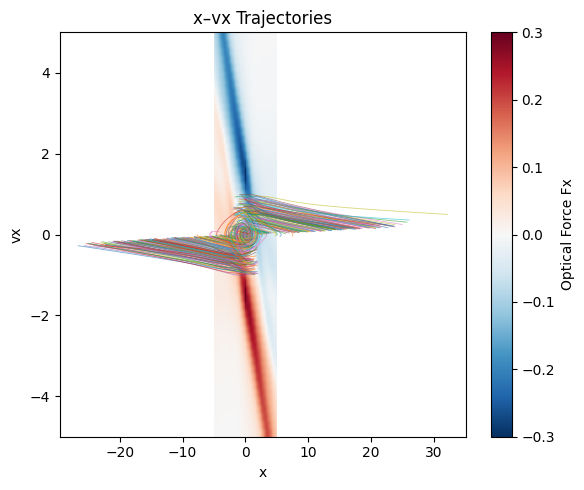

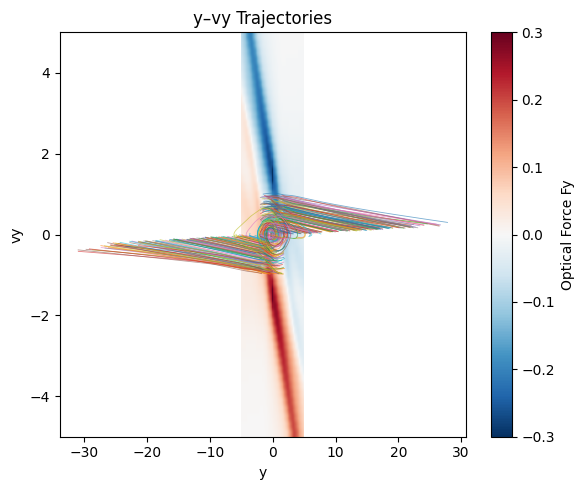

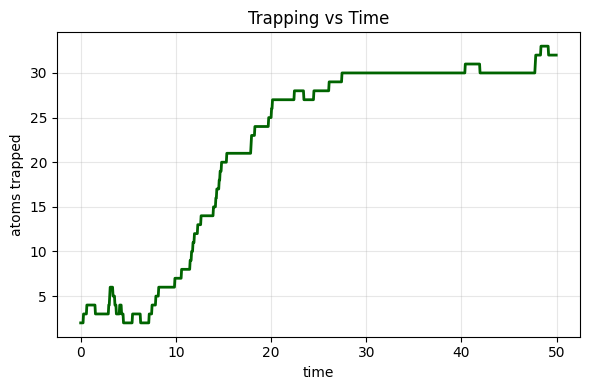

In [90]:
mot.plot_z_vz()
mot.plot_x_vx()
mot.plot_y_vy()
mot.plot_trapped()

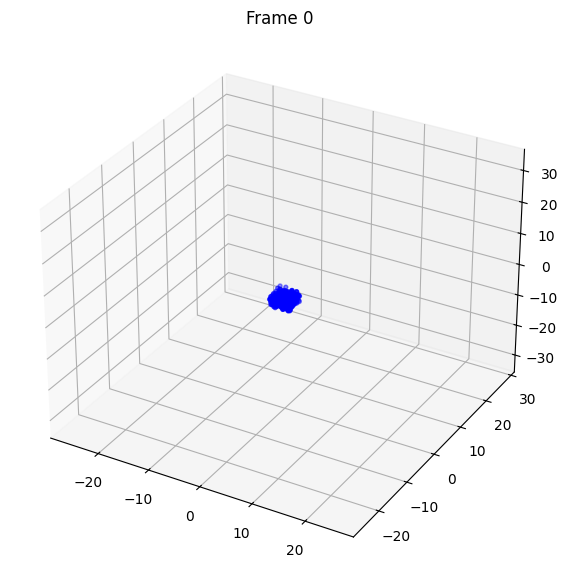

In [83]:
mot.animate_3D()

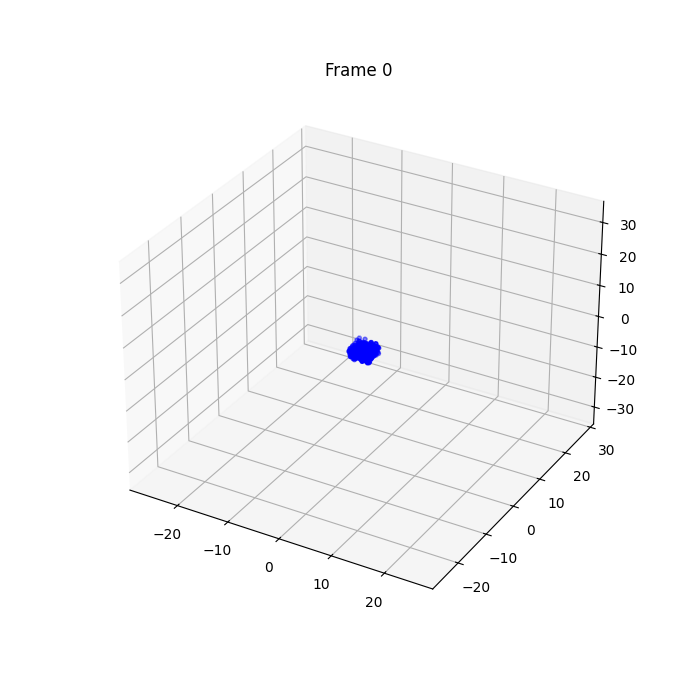

In [84]:
from IPython.display import Image, display
display(Image("mot_animation.gif"))